In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.table import Table

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense

### Training on clean data

In [4]:
with fits.open("../data/20260731/20260731_RT1.fits") as hdul:
    RT1_train = Table(hdul[1].data).to_pandas()
print(RT1_train.shape)

(185781, 22)


### Testing on data with Radio Frequency Interference (RFI)

In [6]:
with fits.open("../data/20260807/20260807_RT1.fits") as hdul:
    RT1_test = Table(hdul[1].data).to_pandas()
print(RT1_test.shape)

(215223, 22)


### Plot Training data

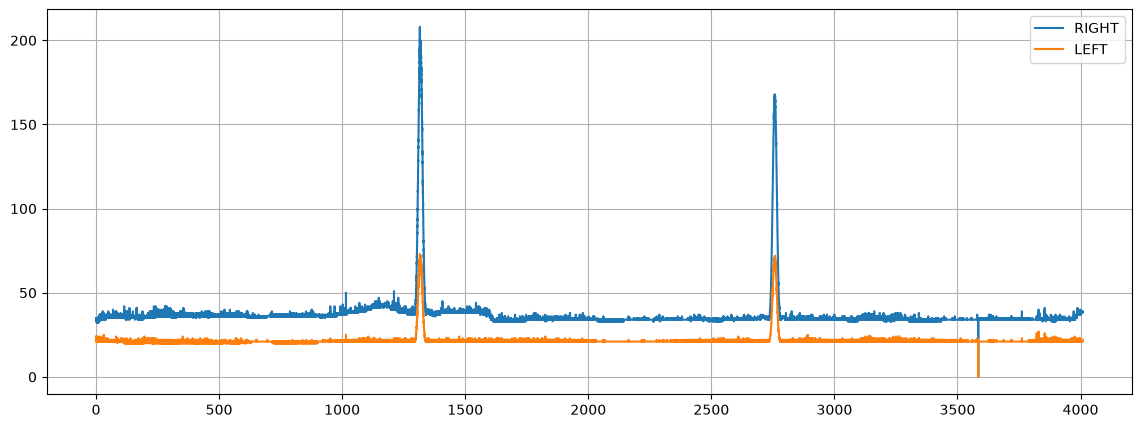

In [7]:
time_train = (
    RT1_train["JD"]
    -
    RT1_train["JD"].iloc[0]
) * 24 * 60

plt.figure(figsize=(14,5))

plt.plot(
    time_train,
    RT1_train["RIGHT_POL"],
    label="RIGHT"
)

plt.plot(
    time_train,
    RT1_train["LEFT_POL"],
    label="LEFT"
)

plt.legend()
plt.grid()

plt.show()

### Normalise training data

In [8]:
right_train = (
    RT1_train["RIGHT_POL"]
    -
    RT1_train["RIGHT_POL"].median()
) / RT1_train["RIGHT_POL"].std()

left_train = (
    RT1_train["LEFT_POL"]
    -
    RT1_train["LEFT_POL"].median()
) / RT1_train["LEFT_POL"].std()

### Normalise testing data using normalization of training data

In [9]:
right_test = (
    RT1_test["RIGHT_POL"]
    -
    RT1_train["RIGHT_POL"].median()
) / RT1_train["RIGHT_POL"].std()

left_test = (
    RT1_test["LEFT_POL"]
    -
    RT1_train["LEFT_POL"].median()
) / RT1_train["LEFT_POL"].std()

### Training cadence

In [11]:
jd_train = RT1_train["JD"].values

dt_train = np.diff(jd_train)

dt_train = np.insert(
    dt_train,
    0,
    np.median(dt_train)
)

dt_train = dt_train * 86400

dt_median = np.median(dt_train)
dt_std = np.std(dt_train)

dt_train = (
    dt_train - dt_median
) / dt_std

### Testing cadence

In [12]:
jd_test_raw = RT1_test["JD"].values

dt_test = np.diff(jd_test_raw)

dt_test = np.insert(
    dt_test,
    0,
    np.median(dt_test)
)

dt_test = dt_test * 86400

dt_test = (
    dt_test - dt_median
) / dt_std

### Set the time window

In [90]:
window = 10

### Training dataset

In [91]:
X_train = []
y_train = []

for i in range(window, len(RT1_train)-1):

    left_seq = left_train.iloc[
        i-window:i
    ].values

    dt_seq = dt_train[
        i-window:i
    ]

    sequence = np.column_stack([
        left_seq,
        dt_seq
    ])

    X_train.append(sequence)

    y_train.append(
        right_train.iloc[i+1]
    )

X_train = np.array(X_train)
y_train = np.array(y_train)

### Testing dataset

In [92]:
X_test = []
y_test = []

jd_target = []

for i in range(window, len(RT1_test)-1):

    left_seq = left_test.iloc[
        i-window:i
    ].values

    dt_seq = dt_test[
        i-window:i
    ]

    sequence = np.column_stack([
        left_seq,
        dt_seq
    ])

    X_test.append(sequence)

    y_test.append(
        right_test.iloc[i+1]
    )

    jd_target.append(
        RT1_test["JD"].iloc[i+1]
    )

X_test = np.array(X_test)
y_test = np.array(y_test)

jd_target = np.array(jd_target)

In [93]:
print(X_train.shape)
print(X_test.shape)

(185770, 10, 2)
(215212, 10, 2)


### Build LSTM

In [94]:
model = Sequential()

model.add(
    LSTM(
        32,
        input_shape=(window,2)
    )
)

model.add(
    Dense(1)
)

model.compile(
    optimizer="adam",
    loss="mse"
)

/mnt/c/Users/manzoni/Desktop/FITS/myvenv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Training

In [95]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=256,
    verbose=1
)

Epoch 1/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.1359 - val_loss: 0.0078
Epoch 2/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0090 - val_loss: 0.0084
Epoch 3/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0067 - val_loss: 0.0092
Epoch 4/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0062 - val_loss: 0.0094
Epoch 5/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0060 - val_loss: 0.0118
Epoch 6/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0058 - val_loss: 0.0102
Epoch 7/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0056 - val_loss: 0.0092
Epoch 8/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0055 - val_loss: 0.0097
Epoch 9/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0055 - val_loss: 0.0086
Epoch 10/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0054 - val_loss: 0.0091
Epoch 11/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0054 - val_loss: 0.0085
Epoch 12/15
654/654 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

### Predict

In [96]:
pred = (
    model
    .predict(X_test)
    .flatten()
)

6726/6726 ━━━━━━━━━━━━━━━━━━━━ 5s 704us/step


### Plot predictions

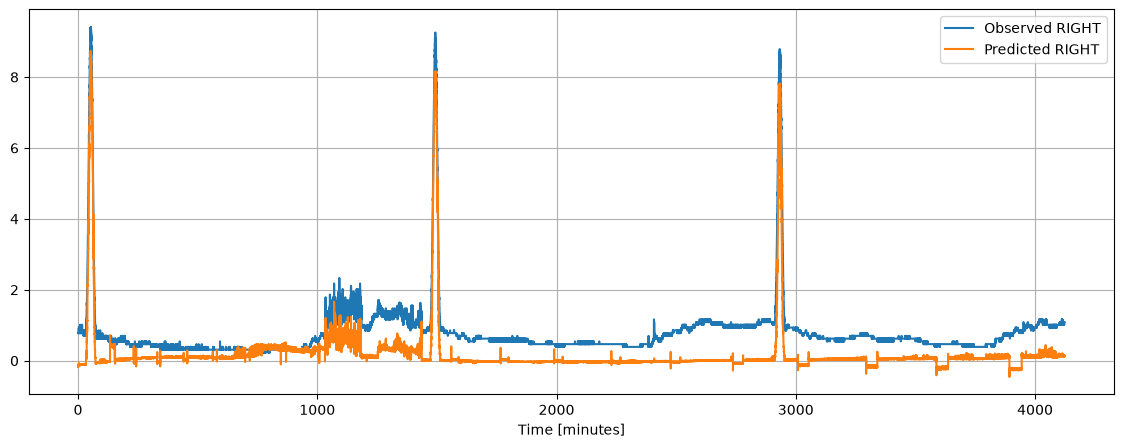

In [97]:
time_test_minutes = (
    jd_target
    -
    RT1_test["JD"].iloc[0]
) * 24 * 60

plt.figure(figsize=(14,5))

plt.plot(
    time_test_minutes,
    y_test,
    label="Observed RIGHT"
)

plt.plot(
    time_test_minutes,
    pred,
    label="Predicted RIGHT"
)

plt.xlabel("Time [minutes]")

plt.legend()
plt.grid()

plt.show()

In [98]:
from sklearn.metrics import r2_score

print(
    "R² =",
    r2_score(y_test, pred)
)

R² = 0.6056892100207296


### Residuals

In [99]:
residual = (
y_test
-
pred
)

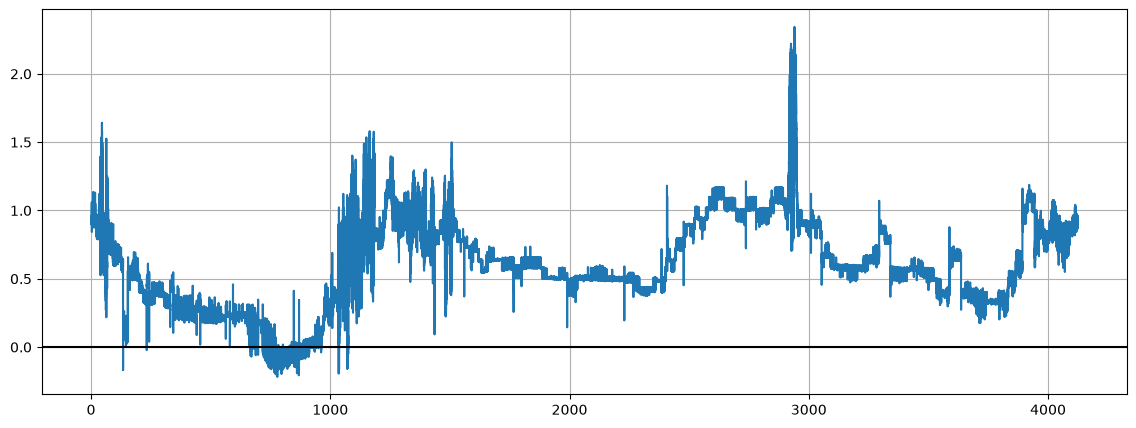

In [100]:
plt.figure(figsize=(14,5))

plt.plot(
    time_test_minutes,
    residual
)

plt.axhline(
    0,
    color="black"
)

plt.grid()

plt.show()

### Anomalies

In [101]:
sigma = residual.std()

anomaly = (
    np.abs(residual)
    >
    3*sigma
)

print(
    "Anomalies:",
    anomaly.sum()
)

Anomalies: 23282


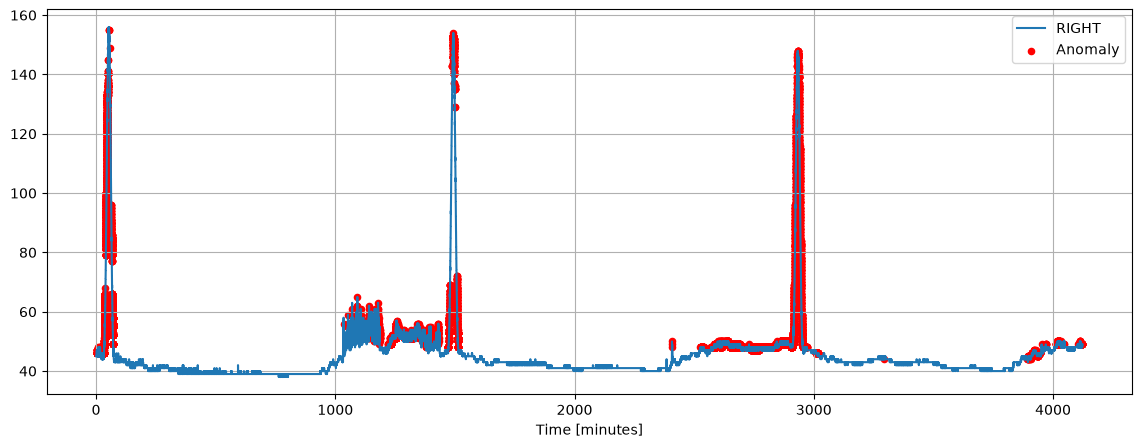

In [102]:
full_time_minutes = (
    RT1_test["JD"]
    -
    RT1_test["JD"].iloc[0]
) * 24 * 60

anomaly_indices = (
    np.where(anomaly)[0]
    + window + 1
)

plt.figure(figsize=(14,5))

plt.plot(
    full_time_minutes,
    RT1_test["RIGHT_POL"],
    label="RIGHT"
)

plt.scatter(
    full_time_minutes.iloc[
        anomaly_indices
    ],
    RT1_test["RIGHT_POL"].iloc[
        anomaly_indices
    ],
    color="red",
    s=20,
    label="Anomaly"
)

plt.xlabel("Time [minutes]")

plt.legend()
plt.grid()

plt.show()